# Prueba del pipeline de fenotipo

Ejecuta paso a paso lo mismo que `Streptococcus26.py`, con la combinación antibiótico/género **más pequeña** (meropenem + *Enterobacter*, 84 muestras) para que corra rápido.

- Todo se guarda en `prueba/` para no mezclarse con los resultados reales.
- Se usan `N_COMP = 10` componentes (el script usa 100) para que los modelos SVD/NMF sean ligeros.
- Las muestras `intermediate` se cuentan como `resistant` dentro de `sparse_fileter` (la tabla original no se modifica).

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
import pandas as pd

from new_camda_functions import (get_data2, available_combinations, sparse_fileter, make_label,
                                 transforms2, get_y_ordinal, split_stratified_into_train_val_test,
                                 train_and_save_binary_models, evaluate_models)

## 1. Configuración

In [2]:
ANTIBIOTICO = "meropenem"
GENERO = "Enterobacter"      # None para filtrar solo por antibiótico
N_COMP = 10                  # componentes de SVD y NMF (el script usa 100)

LABEL = make_label(ANTIBIOTICO, GENERO)
RUTA_FACT = "prueba/data_models/"
RUTA_MODELOS = "prueba/modelos_fenotipo/"
RUTA_RESULTADOS = os.path.join("prueba/resultados_fenotipo", LABEL)
for d in (RUTA_FACT, RUTA_MODELOS, RUTA_RESULTADOS):
    os.makedirs(d, exist_ok=True)
LABEL

'meropenem_Enterobacter'

## 2. Carga de datos (local, `/files2/camda2026/data/`)

In [3]:
%%time
metadata, counts = get_data2()
print("metadata:", metadata.shape, "| counts:", tuple(counts["shape"]))

metadata: (29438, 11) | counts: (np.int64(29438), np.int64(7023103))
CPU times: user 61.4 ms, sys: 16.9 ms, total: 78.3 ms
Wall time: 147 ms


### Combinaciones disponibles (con `intermediate` → `resistant`)
Ordenadas de menor a mayor número de muestras.

In [4]:
combos = available_combinations(metadata)
combos.sort_values("n")

phenotype,antibiotic,gtdb_genus,n,resistant,susceptible
17,meropenem,Enterobacter,84,35,49
16,meropenem,Escherichia,259,28,231
15,ciprofloxacin,Neisseria,304,242,62
14,meropenem,Acinetobacter,596,324,272
13,meropenem,Pseudomonas,712,395,317
12,ceftazidime,Acinetobacter,913,709,204
11,ciprofloxacin,Campylobacter,952,947,5
10,ciprofloxacin,Escherichia,1018,496,522
9,ceftazidime,Pseudomonas,1335,1217,118
8,erythromycin,Streptococcus,1356,647,709


## 3. Filtrado por antibiótico y género

In [5]:
%%time
metadata_original = metadata.copy()

metadata_f, counts_f = sparse_fileter(counts, metadata, antibiotic=ANTIBIOTICO, genus=GENERO)

print("metadata filtrada:", metadata_f.shape, "| counts filtrados:", counts_f.shape)
print("¿metadata original sin cambios?", metadata.equals(metadata_original))

metadata filtrada: (84, 12) | counts filtrados: (84, 7023103)
¿metadata original sin cambios? True
CPU times: user 27.5 s, sys: 48.4 s, total: 1min 15s
Wall time: 1min 20s


In [6]:
# fenotipo original vs. fenotipo usado para entrenar
pd.crosstab(metadata_f["phenotype_original"], metadata_f["phenotype"], margins=True)

phenotype,resistant,susceptible,All
phenotype_original,,,
intermediate,7,0,7
resistant,28,0,28
susceptible,0,49,49
All,35,49,84


## 4. TF-IDF + SVD + NMF
Si los modelos ya existen en `prueba/data_models/` se cargan en lugar de reajustarse.

In [7]:
%%time
exist_vect = os.path.exists(os.path.join(RUTA_FACT, f"tfidf_{LABEL}.pkl"))
exist_fact = exist_vect and all(os.path.exists(os.path.join(RUTA_FACT, f"{m}_{LABEL}.pkl"))
                                for m in ("svd", "nmf"))
print("tfidf existente:", exist_vect, "| svd/nmf existentes:", exist_fact)

X_tfidf, tfidf_vect, amr_lsa, amr_nmf = transforms2(
    amr_count=counts_f, data_label=LABEL, only_counts=False,
    exist_fact=exist_fact, exist_vect=exist_vect,
    fact_path=RUTA_FACT, n_comp=N_COMP, index=metadata_f.index)

amr_lsa.head()

tfidf existente: False | svd/nmf existentes: False
tfidf hecho
inicia svd
terminó svd
inicia nmf
terminó nmf
amr inicia
CPU times: user 14min 41s, sys: 38 s, total: 15min 19s
Wall time: 1min 29s


,0,1,2,3,4,5,6,7,8,9
accession,,,,,,,,,,
BVBRC_550.2162,0.793590,-0.239783,-0.434311,-0.038631,-0.016957,-0.069273,0.086177,0.017617,0.016976,-0.007379
ERZ4207374,0.720825,-0.171277,-0.203077,0.009088,-0.001824,0.048946,-0.095721,-0.005056,-0.014499,-0.000167
ERZ4207375,0.823827,-0.259054,-0.471589,-0.060934,-0.003768,-0.057679,0.109840,0.014222,0.015437,0.021992
ERZ4207377,0.821763,-0.259239,-0.472204,-0.060990,-0.003521,-0.058004,0.110336,0.014349,0.015448,0.022495
ERZ4207378,0.824386,-0.259318,-0.472350,-0.061158,-0.003640,-0.057845,0.110161,0.014261,0.015551,0.022198


## 5. Variable respuesta

In [8]:
Y = get_y_ordinal(metadata=metadata_f, ordinal=False)

# X y Y deben tener las mismas muestras en el mismo orden
assert amr_lsa.index.equals(Y.index) and amr_nmf.index.equals(Y.index), "X y Y desalineados"
Y.value_counts()

phenotype
susceptible    49
resistant      35
Name: count, dtype: int64

## 6. Partición 80/20, entrenamiento y evaluación (SVD y NMF)
Las matrices de confusión se muestran aquí y también se guardan como `.png` en `prueba/resultados_fenotipo/`.


################ LSA ################
train: (67, 10) | test: (17, 10)
Entrenando RandomForest...
    RandomForest: score CV (accuracy) = 0.8495 | {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Entrenando KNN...
    KNN: score CV (accuracy) = 0.8637 | {'n_neighbors': 5, 'weights': 'distance'}
Entrenando LogisticRegression...
    LogisticRegression: score CV (accuracy) = 0.7912 | {'C': 10, 'solver': 'liblinear'}
Entrenando SVC...
    SVC: score CV (accuracy) = 0.8363 | {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Entrenando LASSO...


/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


    LASSO: score CV (accuracy) = 0.8066 | {'C': 10, 'solver': 'liblinear'}
===== KNN_meropenem_Enterobacter_lsa =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



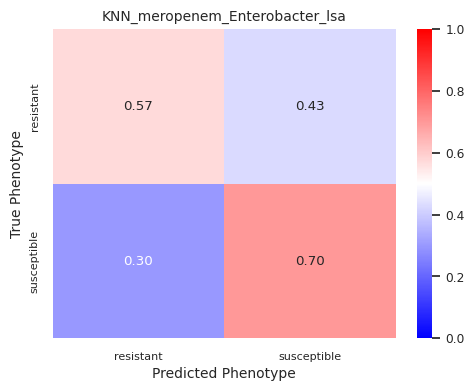

===== LASSO_meropenem_Enterobacter_lsa =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



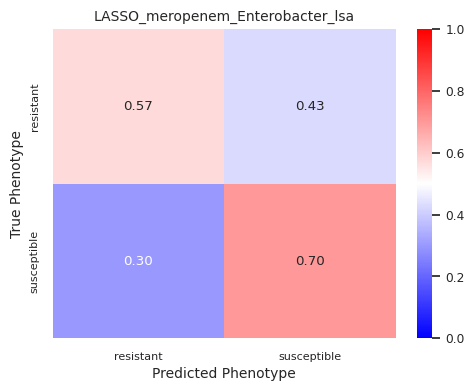

===== LogisticRegression_meropenem_Enterobacter_lsa =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



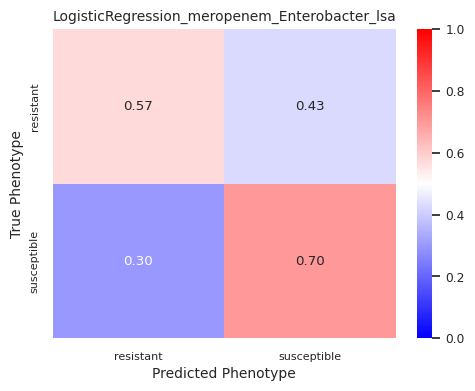

===== RandomForest_meropenem_Enterobacter_lsa =====
              precision    recall  f1-score   support

   resistant       0.50      0.57      0.53         7
 susceptible       0.67      0.60      0.63        10

    accuracy                           0.59        17
   macro avg       0.58      0.59      0.58        17
weighted avg       0.60      0.59      0.59        17



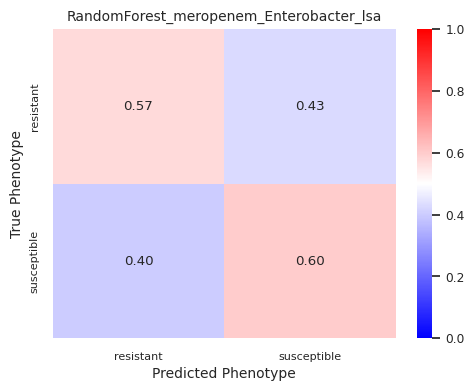

===== SVC_meropenem_Enterobacter_lsa =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



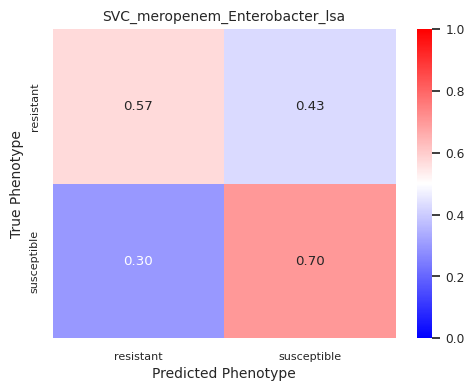

Scores guardados en 'prueba/resultados_fenotipo/meropenem_Enterobacter/scores_meropenem_Enterobacter_lsa.txt'.

################ NMF ################
train: (67, 10) | test: (17, 10)
Entrenando RandomForest...
    RandomForest: score CV (accuracy) = 0.7615 | {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Entrenando KNN...
    KNN: score CV (accuracy) = 0.8066 | {'n_neighbors': 5, 'weights': 'distance'}
Entrenando LogisticRegression...
    LogisticRegression: score CV (accuracy) = 0.8066 | {'C': 10, 'solver': 'liblinear'}
Entrenando SVC...
    SVC: score CV (accuracy) = 0.8352 | {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Entrenando LASSO...
    LASSO: score CV (accuracy) = 0.8209 | {'C': 100, 'solver': 'saga'}
===== KNN_meropenem_Enterobacter_nmf =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17


/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


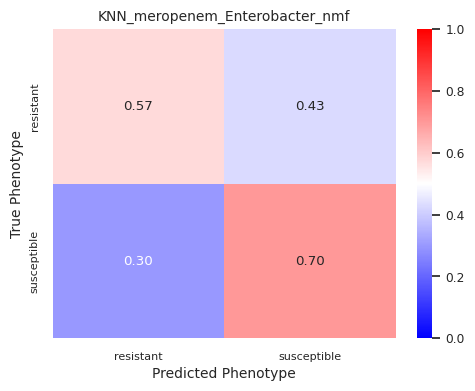

===== LASSO_meropenem_Enterobacter_nmf =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



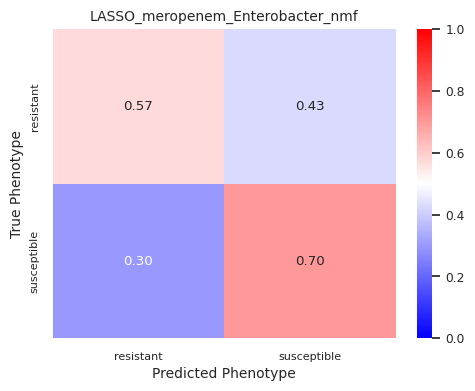

===== LogisticRegression_meropenem_Enterobacter_nmf =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



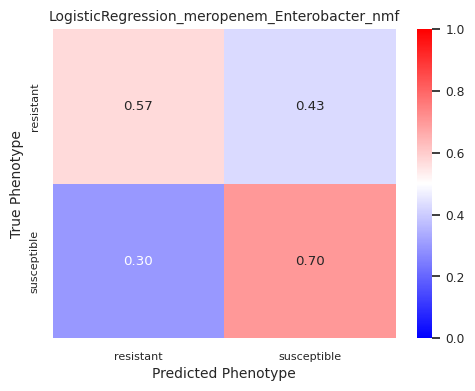

===== RandomForest_meropenem_Enterobacter_nmf =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



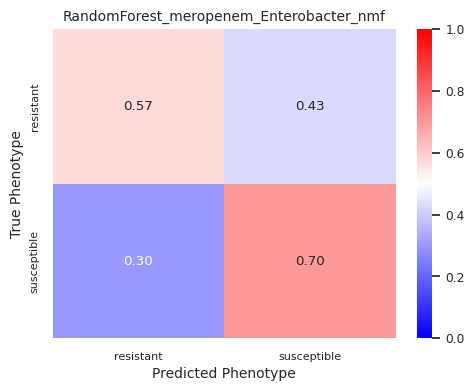

===== SVC_meropenem_Enterobacter_nmf =====
              precision    recall  f1-score   support

   resistant       0.57      0.57      0.57         7
 susceptible       0.70      0.70      0.70        10

    accuracy                           0.65        17
   macro avg       0.64      0.64      0.64        17
weighted avg       0.65      0.65      0.65        17



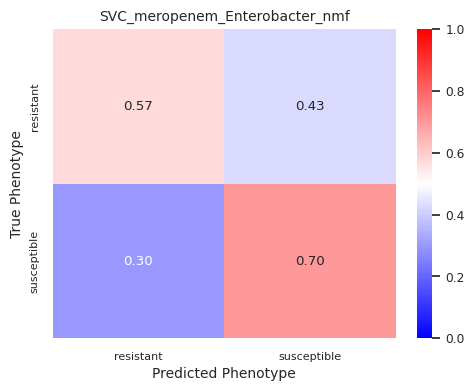

Scores guardados en 'prueba/resultados_fenotipo/meropenem_Enterobacter/scores_meropenem_Enterobacter_nmf.txt'.
CPU times: user 5.06 s, sys: 4.64 s, total: 9.7 s
Wall time: 16.1 s


In [9]:
%%time
todos = []
for rep, X in (("lsa", amr_lsa), ("nmf", amr_nmf)):
    label_rep = f"{LABEL}_{rep}"
    print(f"\n################ {rep.upper()} ################")

    X_train, y_train, _, _, X_test, y_test, class_w, _ = split_stratified_into_train_val_test(
        X, Y, .80, 0, .20, std=False, two_subsets=True, random_state=42)
    print("train:", X_train.shape, "| test:", X_test.shape)

    train_and_save_binary_models(X_train, y_train, label_rep, output_dir=RUTA_MODELOS,
                                 params_dir=RUTA_RESULTADOS)

    scores = evaluate_models(X_test, y_test, data_label=label_rep, models_dir=RUTA_MODELOS,
                             results_dir=RUTA_RESULTADOS, show_plots=True)
    scores.insert(1, "Representación", rep)
    todos.append(scores)

## 7. Resumen

In [10]:
resumen = pd.concat(todos, ignore_index=True).sort_values("F1 (macro)", ascending=False)
resumen.to_csv(os.path.join(RUTA_RESULTADOS, f"resumen_{LABEL}.csv"), index=False)
resumen

,Modelo,Representación,Accuracy,F1 (weighted),F1 (macro),Precision (weighted),Recall (weighted)
0,KNN_meropenem_Enterobacter_lsa,lsa,0.647059,0.647059,0.635714,0.647059,0.647059
1,LASSO_meropenem_Enterobacter_lsa,lsa,0.647059,0.647059,0.635714,0.647059,0.647059
2,LogisticRegression_meropenem_Enterobacter_lsa,lsa,0.647059,0.647059,0.635714,0.647059,0.647059
4,SVC_meropenem_Enterobacter_lsa,lsa,0.647059,0.647059,0.635714,0.647059,0.647059
5,KNN_meropenem_Enterobacter_nmf,nmf,0.647059,0.647059,0.635714,0.647059,0.647059
6,LASSO_meropenem_Enterobacter_nmf,nmf,0.647059,0.647059,0.635714,0.647059,0.647059
8,RandomForest_meropenem_Enterobacter_nmf,nmf,0.647059,0.647059,0.635714,0.647059,0.647059
7,LogisticRegression_meropenem_Enterobacter_nmf,nmf,0.647059,0.647059,0.635714,0.647059,0.647059
9,SVC_meropenem_Enterobacter_nmf,nmf,0.647059,0.647059,0.635714,0.647059,0.647059
3,RandomForest_meropenem_Enterobacter_lsa,lsa,0.588235,0.591125,0.582456,0.598039,0.588235


In [11]:
# archivos generados
sorted(os.listdir(RUTA_RESULTADOS))

['matriz_confusion_KNN_meropenem_Enterobacter_lsa.png',
 'matriz_confusion_KNN_meropenem_Enterobacter_nmf.png',
 'matriz_confusion_LASSO_meropenem_Enterobacter_lsa.png',
 'matriz_confusion_LASSO_meropenem_Enterobacter_nmf.png',
 'matriz_confusion_LogisticRegression_meropenem_Enterobacter_lsa.png',
 'matriz_confusion_LogisticRegression_meropenem_Enterobacter_nmf.png',
 'matriz_confusion_RandomForest_meropenem_Enterobacter_lsa.png',
 'matriz_confusion_RandomForest_meropenem_Enterobacter_nmf.png',
 'matriz_confusion_SVC_meropenem_Enterobacter_lsa.png',
 'matriz_confusion_SVC_meropenem_Enterobacter_nmf.png',
 'parametros_optimos_meropenem_Enterobacter_lsa.txt',
 'parametros_optimos_meropenem_Enterobacter_nmf.txt',
 'reporte_KNN_meropenem_Enterobacter_lsa.txt',
 'reporte_KNN_meropenem_Enterobacter_nmf.txt',
 'reporte_LASSO_meropenem_Enterobacter_lsa.txt',
 'reporte_LASSO_meropenem_Enterobacter_nmf.txt',
 'reporte_LogisticRegression_meropenem_Enterobacter_lsa.txt',
 'reporte_LogisticRegressi

## Correr lo mismo con el script (en una `screen`)

```bash
screen -S fenotipo
python -u Model_maker.py --antibiotico ciprofloxacin --genero Neisseria	 --n_comp 10
# Ctrl+A, D para salir sin detenerlo
tail -f resultados_fenotipo/meropenem_Enterobacter/ejecucion.log
```

El script guarda en `data_models/`, `modelos_fenotipo/` y `resultados_fenotipo/` (no en `prueba/`).